<a href="https://colab.research.google.com/github/preethikris/BMSCE-DATA-VISUALIZATION/blob/main/Data_Visualization_lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


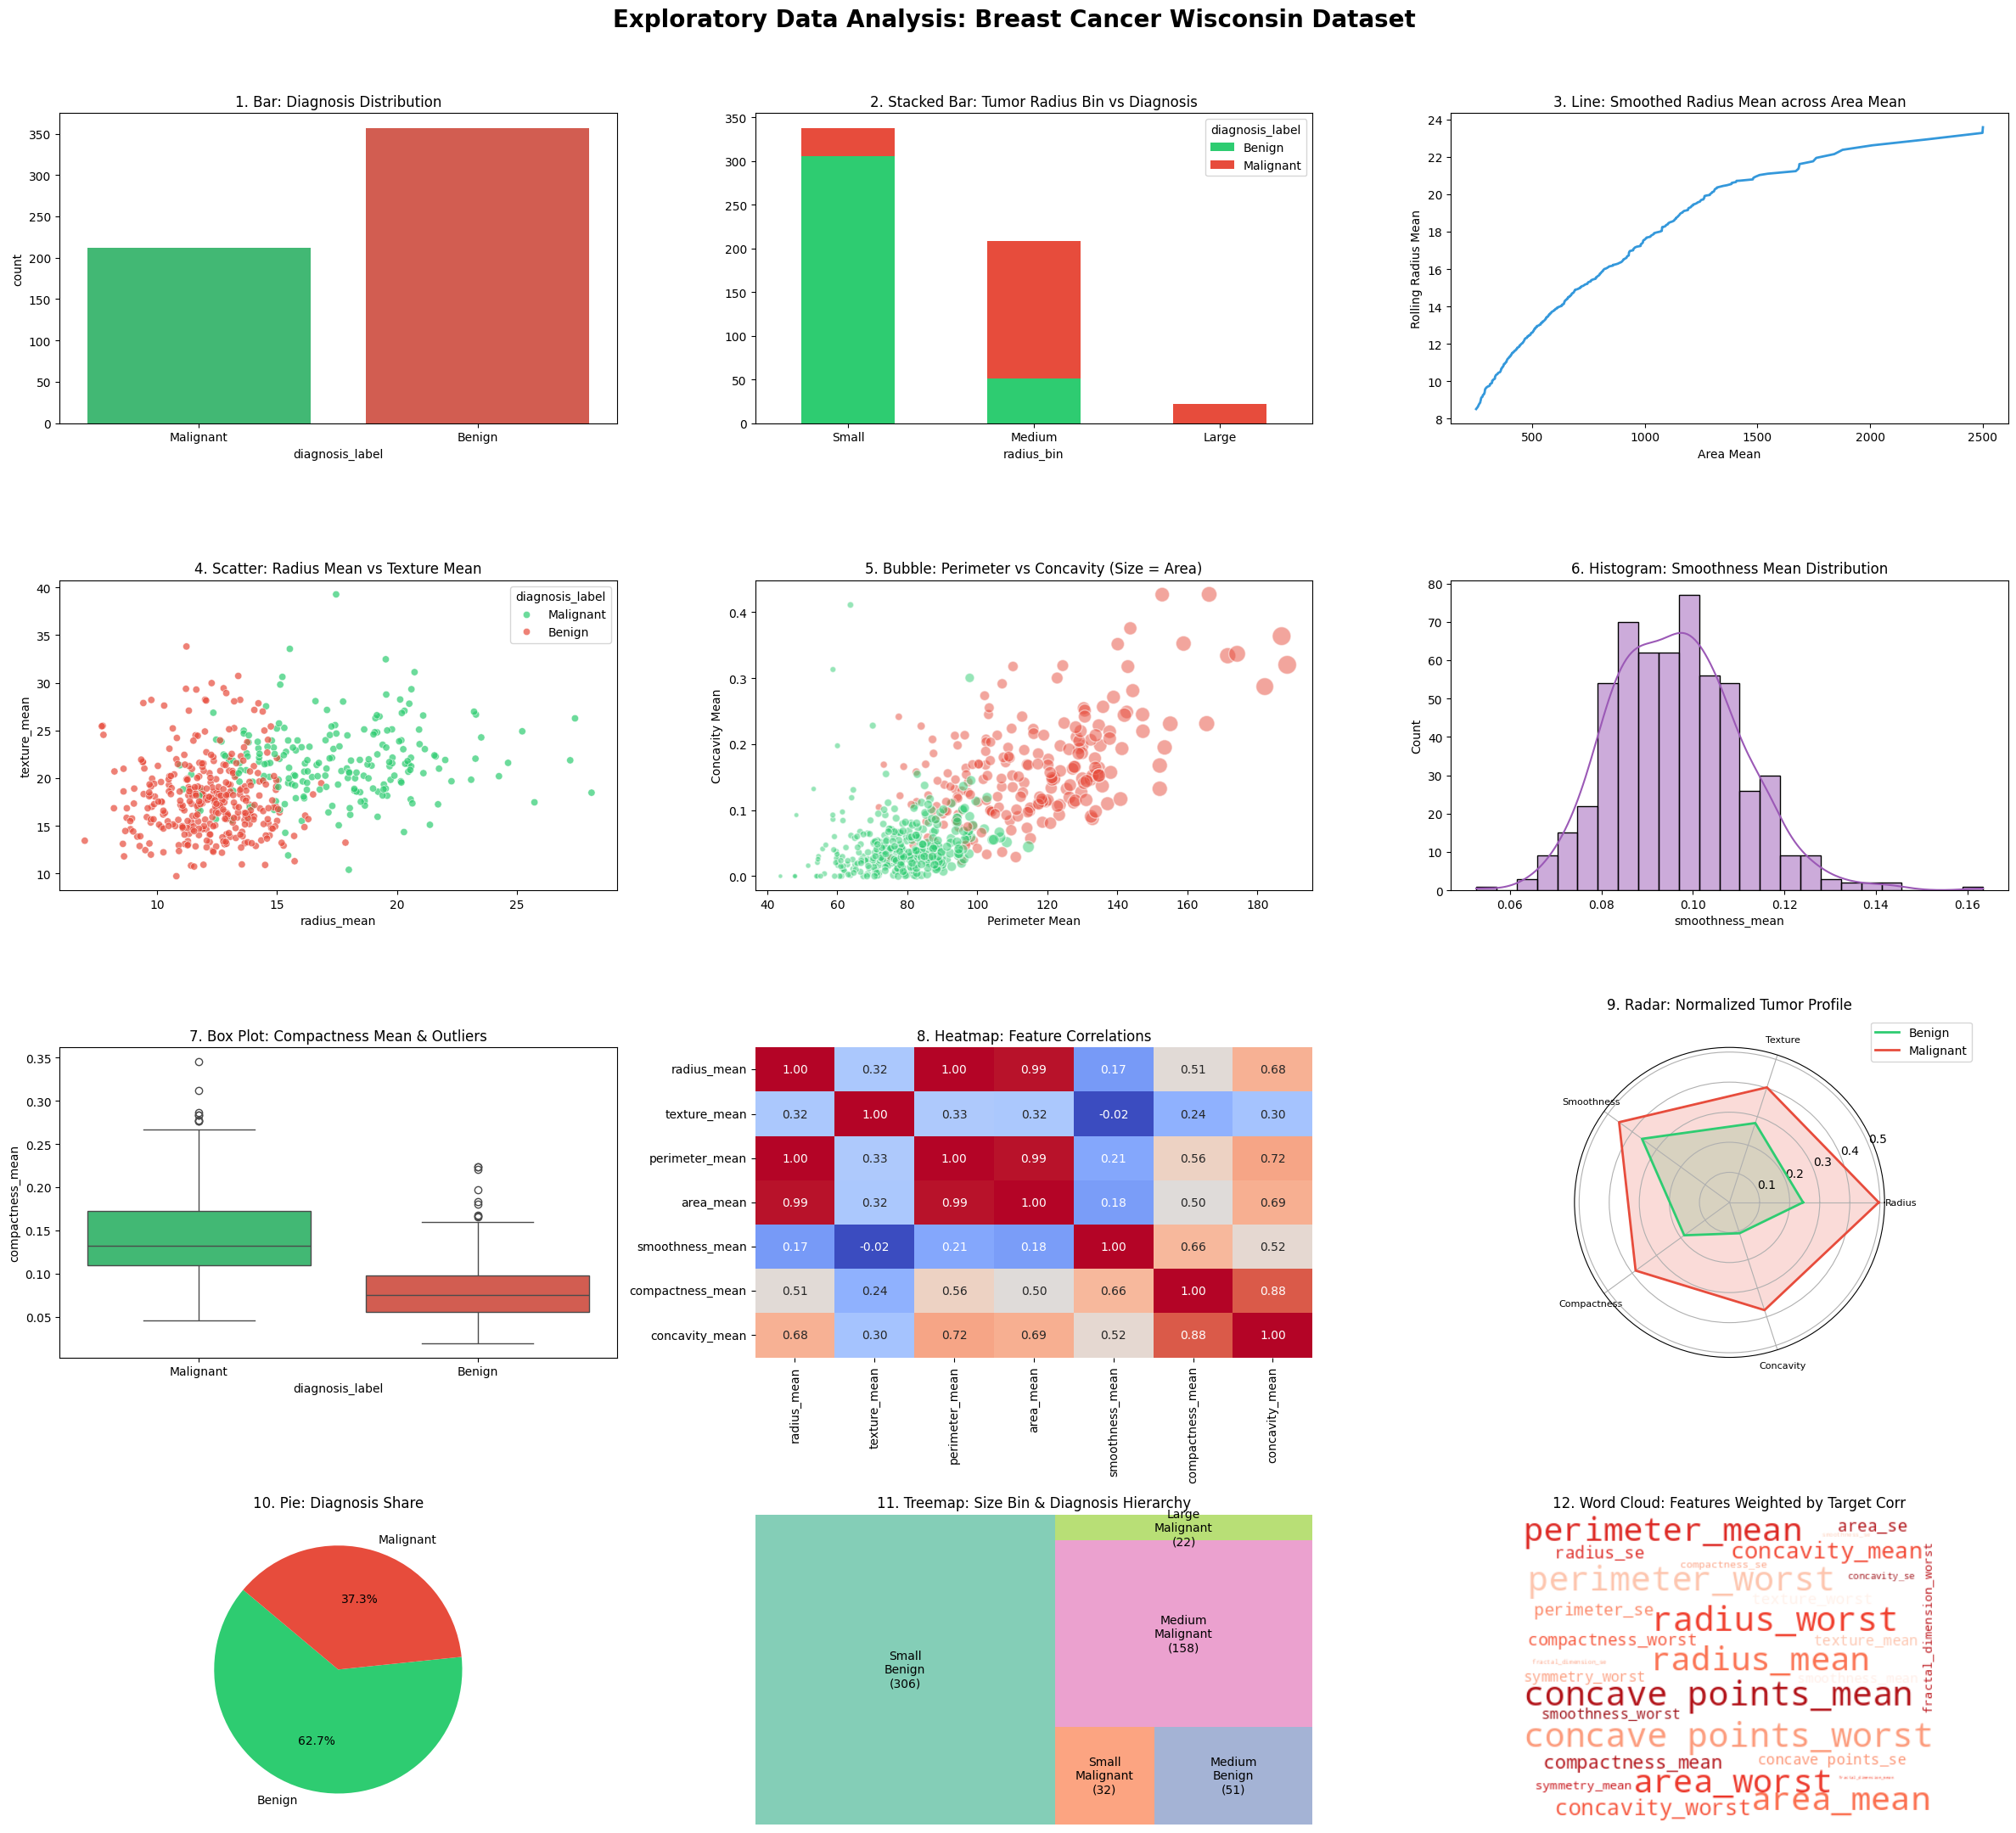

In [3]:
!pip install -q squarify

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
from wordcloud import WordCloud
from math import pi
import os

# 1. Load Dataset directly via KaggleHub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

# Data Cleaning
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df['diagnosis_label'] = df['diagnosis'].map({'M': 'Malignant', 'B': 'Benign'})
df['radius_bin'] = pd.cut(df['radius_mean'], bins=3, labels=['Small', 'Medium', 'Large'])

# Set up 4x3 Subplot Grid
fig = plt.figure(figsize=(24, 22))
fig.suptitle('Exploratory Data Analysis: Breast Cancer Wisconsin Dataset', fontsize=20, fontweight='bold', y=0.98)

# 1. Bar Chart: Diagnosis Counts
ax1 = fig.add_subplot(4, 3, 1)
sns.countplot(data=df, x='diagnosis_label', hue='diagnosis_label', palette=['#2ecc71', '#e74c3c'], legend=False, ax=ax1)
ax1.set_title('1. Bar: Diagnosis Distribution')

# 2. Stacked Bar Chart: Radius Size Category by Diagnosis
ax2 = fig.add_subplot(4, 3, 2)
ct = pd.crosstab(df['radius_bin'], df['diagnosis_label'])
ct.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=ax2)
ax2.set_title('2. Stacked Bar: Tumor Radius Bin vs Diagnosis')
ax2.tick_params(axis='x', rotation=0)

# 3. Line Chart: Moving Average of Radius Mean sorted by Area Mean
ax3 = fig.add_subplot(4, 3, 3)
df_sorted = df.sort_values('area_mean').reset_index(drop=True)
ax3.plot(df_sorted['area_mean'], df_sorted['radius_mean'].rolling(20).mean(), color='#3498db', linewidth=2)
ax3.set_title('3. Line: Smoothed Radius Mean across Area Mean')
ax3.set_xlabel('Area Mean')
ax3.set_ylabel('Rolling Radius Mean')

# 4. Scatter Plot: Radius Mean vs Texture Mean
ax4 = fig.add_subplot(4, 3, 4)
sns.scatterplot(data=df, x='radius_mean', y='texture_mean', hue='diagnosis_label', palette=['#2ecc71', '#e74c3c'], alpha=0.7, ax=ax4)
ax4.set_title('4. Scatter: Radius Mean vs Texture Mean')

# 5. Bubble Chart: Concavity vs Perimeter (Size = Area Mean)
ax5 = fig.add_subplot(4, 3, 5)
colors = df['diagnosis'].map({'M': '#e74c3c', 'B': '#2ecc71'})
ax5.scatter(df['perimeter_mean'], df['concavity_mean'], s=df['area_mean']/10, c=colors, alpha=0.5, edgecolors='w')
ax5.set_title('5. Bubble: Perimeter vs Concavity (Size = Area)')
ax5.set_xlabel('Perimeter Mean')
ax5.set_ylabel('Concavity Mean')

# 6. Histogram: Distribution of Smoothness Mean
ax6 = fig.add_subplot(4, 3, 6)
sns.histplot(data=df, x='smoothness_mean', kde=True, color='#9b59b6', ax=ax6)
ax6.set_title('6. Histogram: Smoothness Mean Distribution')

# 7. Box Plot: Compactness Mean by Diagnosis (Outlier Detection)
ax7 = fig.add_subplot(4, 3, 7)
sns.boxplot(data=df, x='diagnosis_label', y='compactness_mean', hue='diagnosis_label', palette=['#2ecc71', '#e74c3c'], legend=False, ax=ax7)
ax7.set_title('7. Box Plot: Compactness Mean & Outliers')

# 8. Heatmap: Correlation Matrix of Mean Features
ax8 = fig.add_subplot(4, 3, 8)
mean_cols = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean']
sns.heatmap(df[mean_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=False, ax=ax8)
ax8.set_title('8. Heatmap: Feature Correlations')

# 9. Radar Chart: Normalized Feature Comparison (Benign vs Malignant)
ax9 = fig.add_subplot(4, 3, 9, polar=True)
radar_cols = ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean']
df_norm = df.copy()
for col in radar_cols:
    df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
means = df_norm.groupby('diagnosis_label')[radar_cols].mean()

angles = [n / float(len(radar_cols)) * 2 * pi for n in range(len(radar_cols))]
angles += angles[:1]
for label, color in zip(['Benign', 'Malignant'], ['#2ecc71', '#e74c3c']):
    values = means.loc[label].values.flatten().tolist()
    values += values[:1]
    ax9.plot(angles, values, linewidth=2, label=label, color=color)
    ax9.fill(angles, values, color=color, alpha=0.2)
ax9.set_xticks(angles[:-1])
ax9.set_xticklabels(['Radius', 'Texture', 'Smoothness', 'Compactness', 'Concavity'], fontsize=8)
ax9.set_title('9. Radar: Normalized Tumor Profile', y=1.1)
ax9.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

# 10. Pie Chart: Proportion of Diagnosis
ax10 = fig.add_subplot(4, 3, 10)
diag_counts = df['diagnosis_label'].value_counts()
ax10.pie(diag_counts, labels=diag_counts.index, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=140)
ax10.set_title('10. Pie: Diagnosis Share')

# 11. Treemap: Breakdown by Radius Size and Diagnosis
ax11 = fig.add_subplot(4, 3, 11)
tree_df = df.groupby(['radius_bin', 'diagnosis_label'], observed=False).size().reset_index(name='count')
tree_df = tree_df[tree_df['count'] > 0]
labels = [f"{r}\n{d}\n({c})" for r, d, c in zip(tree_df['radius_bin'], tree_df['diagnosis_label'], tree_df['count'])]
squarify.plot(sizes=tree_df['count'], label=labels, alpha=0.8, color=sns.color_palette('Set2', len(tree_df)), ax=ax11)
ax11.axis('off')
ax11.set_title('11. Treemap: Size Bin & Diagnosis Hierarchy')

# 12. Word Cloud: Feature Importance/Descriptors weighted by Correlation with Target
ax12 = fig.add_subplot(4, 3, 12)
df['target'] = df['diagnosis'].map({'M': 1, 'B': 0})
corrs = df.drop(columns=['diagnosis', 'diagnosis_label', 'radius_bin']).corr()['target'].abs().drop('target')
wc = WordCloud(width=400, height=300, background_color='white', colormap='Reds').generate_from_frequencies(corrs.to_dict())
ax12.imshow(wc, interpolation='bilinear')
ax12.axis('off')
ax12.set_title('12. Word Cloud: Features Weighted by Target Corr')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

100%|██████████| 11.2k/11.2k [00:00<00:00, 13.7MB/s]

Extracting files...


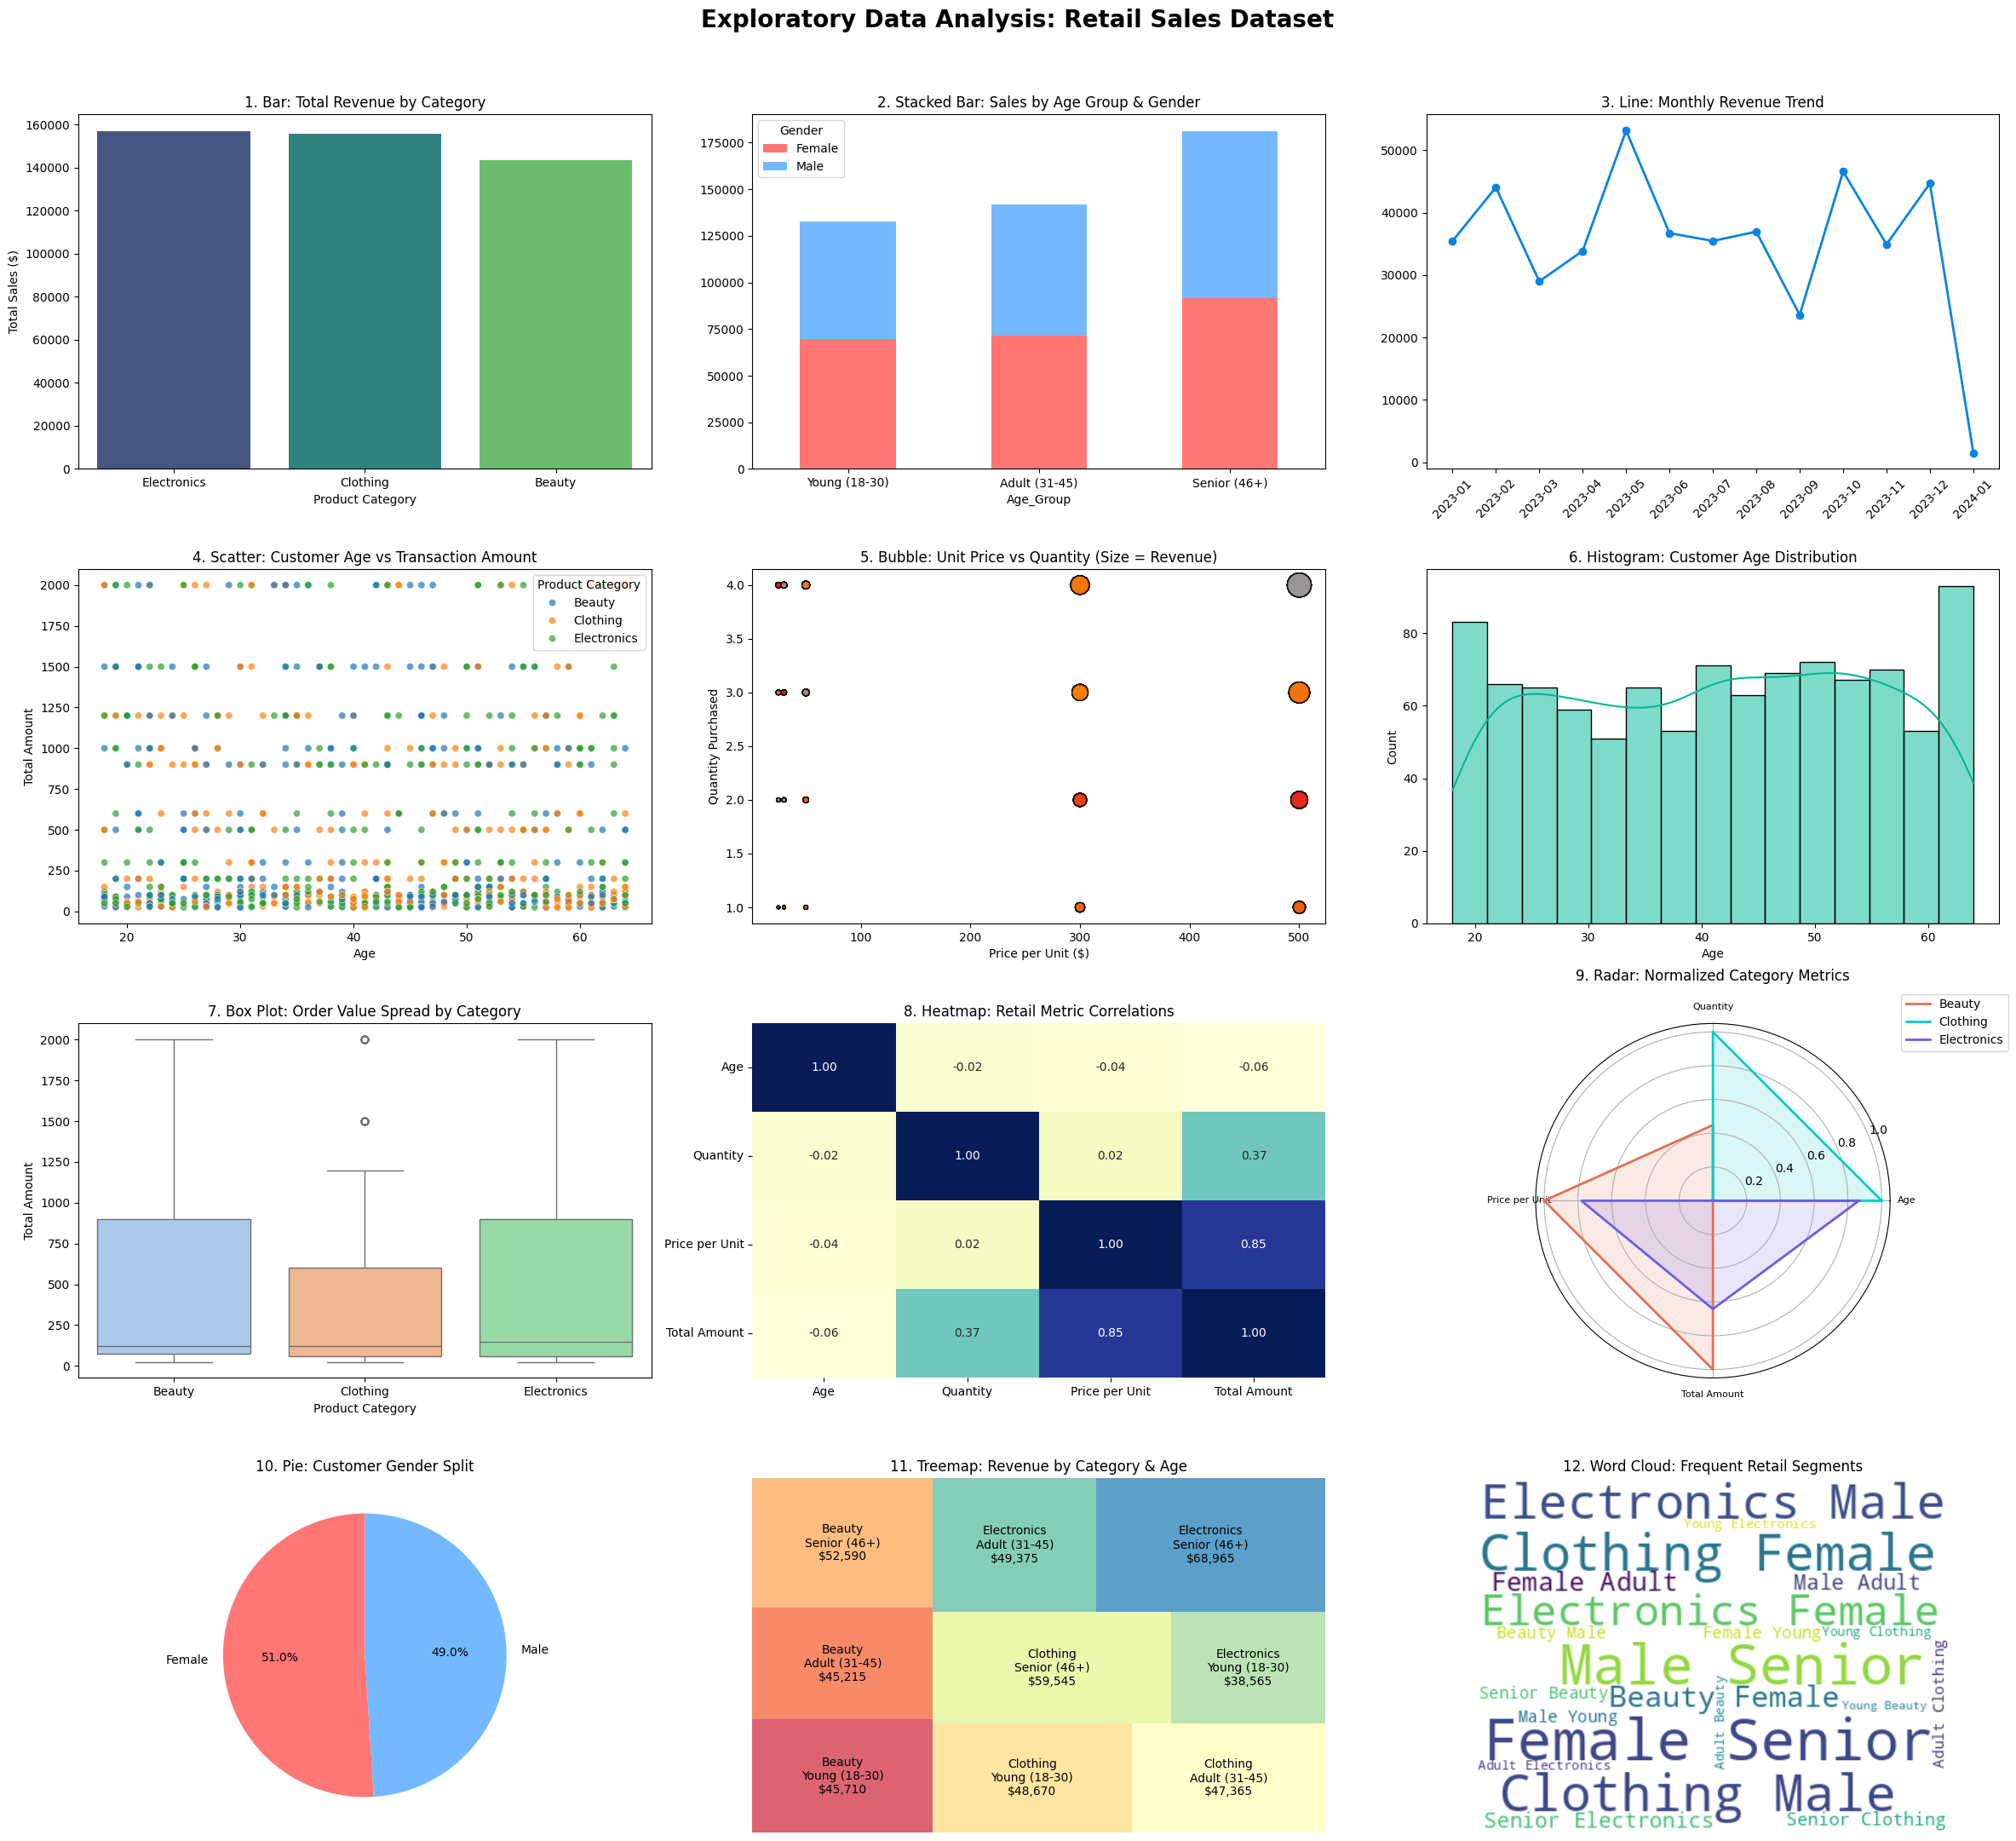

In [5]:
!pip install -q squarify

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
from wordcloud import WordCloud
from math import pi
import os

# 1. Load Dataset directly via KaggleHub
path = kagglehub.dataset_download("mohammadtalib786/retail-sales-dataset")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

# Data Cleaning & Feature Engineering
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Age_Group'] = pd.cut(df['Age'], bins=[17, 30, 45, 65], labels=['Young (18-30)', 'Adult (31-45)', 'Senior (46+)'])

fig = plt.figure(figsize=(24, 22))
fig.suptitle('Exploratory Data Analysis: Retail Sales Dataset', fontsize=20, fontweight='bold', y=0.98)

# 1. Bar Chart: Total Revenue by Product Category
ax1 = fig.add_subplot(4, 3, 1)
cat_rev = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
sns.barplot(x=cat_rev.index, y=cat_rev.values, hue=cat_rev.index, palette='viridis', legend=False, ax=ax1)
ax1.set_title('1. Bar: Total Revenue by Category')
ax1.set_ylabel('Total Sales ($)')

# 2. Stacked Bar Chart: Revenue by Age Group & Gender
ax2 = fig.add_subplot(4, 3, 2)
ct = df.pivot_table(index='Age_Group', columns='Gender', values='Total Amount', aggfunc='sum', observed=False)
ct.plot(kind='bar', stacked=True, color=['#ff7675', '#74b9ff'], ax=ax2)
ax2.set_title('2. Stacked Bar: Sales by Age Group & Gender')
ax2.tick_params(axis='x', rotation=0)

# 3. Line Chart: Monthly Revenue Trend
ax3 = fig.add_subplot(4, 3, 3)
monthly_sales = df.groupby('Month')['Total Amount'].sum().sort_index()
ax3.plot(monthly_sales.index, monthly_sales.values, marker='o', color='#0984e3', linewidth=2)
ax3.set_title('3. Line: Monthly Revenue Trend')
ax3.tick_params(axis='x', rotation=45)

# 4. Scatter Plot: Age vs Total Amount
ax4 = fig.add_subplot(4, 3, 4)
sns.scatterplot(data=df, x='Age', y='Total Amount', hue='Product Category', alpha=0.7, ax=ax4)
ax4.set_title('4. Scatter: Customer Age vs Transaction Amount')

# 5. Bubble Chart: Price per Unit vs Quantity (Size = Total Amount)
ax5 = fig.add_subplot(4, 3, 5)
cat_codes = df['Product Category'].astype('category').cat.codes
ax5.scatter(df['Price per Unit'], df['Quantity'], s=df['Total Amount']/5, c=cat_codes, cmap='Set1', alpha=0.6, edgecolors='k')
ax5.set_title('5. Bubble: Unit Price vs Quantity (Size = Revenue)')
ax5.set_xlabel('Price per Unit ($)')
ax5.set_ylabel('Quantity Purchased')

# 6. Histogram: Customer Age Distribution
ax6 = fig.add_subplot(4, 3, 6)
sns.histplot(data=df, x='Age', bins=15, kde=True, color='#00b894', ax=ax6)
ax6.set_title('6. Histogram: Customer Age Distribution')

# 7. Box Plot: Total Amount Distribution by Product Category
ax7 = fig.add_subplot(4, 3, 7)
sns.boxplot(data=df, x='Product Category', y='Total Amount', hue='Product Category', palette='pastel', legend=False, ax=ax7)
ax7.set_title('7. Box Plot: Order Value Spread by Category')

# 8. Heatmap: Numerical Feature Correlations
ax8 = fig.add_subplot(4, 3, 8)
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='YlGnBu', cbar=False, ax=ax8)
ax8.set_title('8. Heatmap: Retail Metric Correlations')

# 9. Radar Chart: Category Performance Profile
ax9 = fig.add_subplot(4, 3, 9, polar=True)
metrics = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
cat_means = df.groupby('Product Category')[metrics].mean()
cat_norm = (cat_means - cat_means.min()) / (cat_means.max() - cat_means.min() + 1e-9)

angles = [n / float(len(metrics)) * 2 * pi for n in range(len(metrics))]
angles += angles[:1]
for cat, color in zip(cat_norm.index, ['#e17055', '#00cec9', '#6c5ce7']):
    vals = cat_norm.loc[cat].values.flatten().tolist()
    vals += vals[:1]
    ax9.plot(angles, vals, linewidth=2, label=cat, color=color)
    ax9.fill(angles, vals, color=color, alpha=0.15)
ax9.set_xticks(angles[:-1])
ax9.set_xticklabels(metrics, fontsize=8)
ax9.set_title('9. Radar: Normalized Category Metrics', y=1.1)
ax9.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))

# 10. Pie Chart: Transaction Share by Gender
ax10 = fig.add_subplot(4, 3, 10)
gender_counts = df['Gender'].value_counts()
ax10.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['#ff7675', '#74b9ff'], startangle=90)
ax10.set_title('10. Pie: Customer Gender Split')

# 11. Treemap: Revenue Share by Category & Age Group
ax11 = fig.add_subplot(4, 3, 11)
tree_df = df.groupby(['Product Category', 'Age_Group'], observed=False)['Total Amount'].sum().reset_index()
labels = [f"{c}\n{a}\n${v:,.0f}" for c, a, v in zip(tree_df['Product Category'], tree_df['Age_Group'], tree_df['Total Amount'])]
squarify.plot(sizes=tree_df['Total Amount'], label=labels, alpha=0.8, color=sns.color_palette('Spectral', len(tree_df)), ax=ax11)
ax11.axis('off')
ax11.set_title('11. Treemap: Revenue by Category & Age')

# 12. Word Cloud: Weighted Category & Demographic Segments
ax12 = fig.add_subplot(4, 3, 12)
text_corpus = " ".join(df['Product Category'] + " " + df['Gender'] + " " + df['Age_Group'].astype(str))
wc = WordCloud(width=400, height=300, background_color='white', colormap='viridis').generate(text_corpus)
ax12.imshow(wc, interpolation='bilinear')
ax12.axis('off')
ax12.set_title('12. Word Cloud: Frequent Retail Segments')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()